In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [27]:


df = pd.read_csv(r"E:\OIBSIP\DataAnalytics-L1-HousePricePrediction\dataset\Housing.csv")


display(df.head())

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [28]:
print("Dataset Shape:", df.shape)
df.info()


Dataset Shape: (545, 13)
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [29]:
# Check missing values in each column

print(df.isnull().sum())

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [30]:
display(df.describe())

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


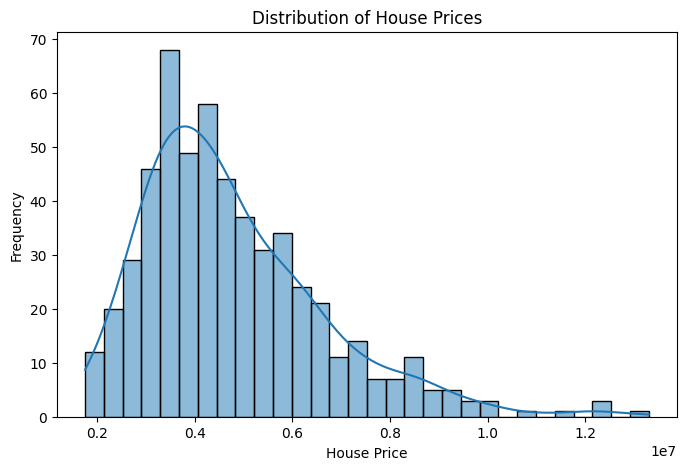

In [31]:


plt.figure(figsize=(8, 5))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

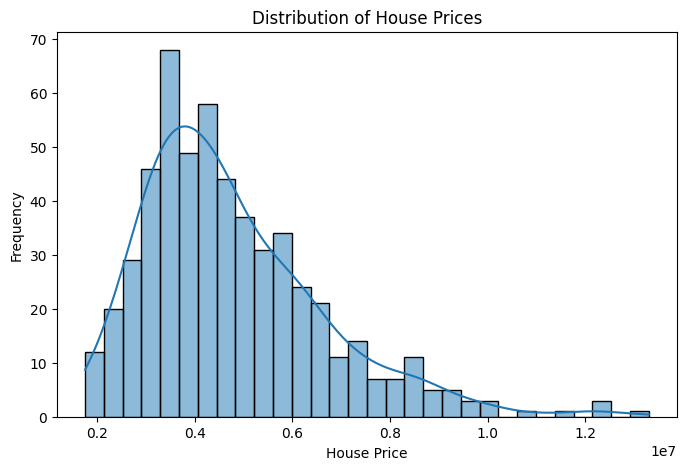

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.savefig("screenshots/price_distribution.png", dpi=300, bbox_inches="tight")

plt.show()


### Feature Selection

The target variable for this project is price, as our objective is to predict the selling price of houses.

The following features will be used as input variables:

- area: Total area of the house.
- bedrooms: Number of bedrooms.
- bathrooms: Number of bathrooms.
- stories: Number of floors.
- mainroad: Whether the house is connected to the main road.
- guestroom: Availability of a guest room.
- basement: Whether the house has a basement.
- hotwaterheating: Availability of hot water heating.
- airconditioning: Availability of air conditioning.
- parking: Number of parking spaces.
- prefarea: Whether the house is in a preferred area.
- furnishingstatus: Furnishing condition of the house.

These features are selected because they describe the size, facilities, and characteristics of a house, which may influence its selling price.

The dataset does not contain exact location names or house age, so these features are not included.


In [33]:
X = df.drop(columns=["price"])
y = df["price"]
X = pd.get_dummies(X, drop_first=True, dtype=int)
display(X.head())

print("Shape after encoding:", X.shape)

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,7420,4,1,2,2,1,1,1,0,1,0,0,0


Shape after encoding: (545, 13)


In [34]:
print("Shape after encoding:", X.shape)

Shape after encoding: (545, 13)


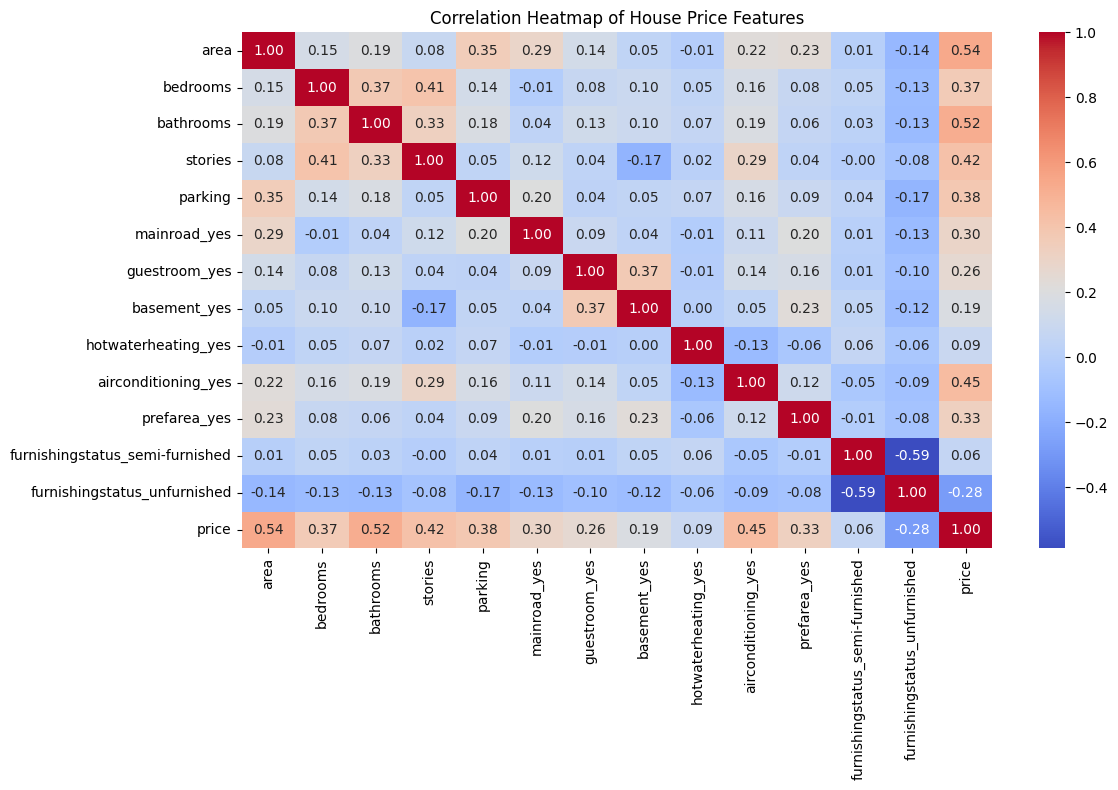

In [35]:
correlation_data = pd.concat([X, y], axis=1)
correlation_matrix = correlation_data.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of House Price Features")
plt.tight_layout()

plt.savefig("screenshots/correlation_heatmap.png", dpi=300)

plt.show()

In [36]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check the shapes of the datasets

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (436, 13)
Testing features: (109, 13)
Training target: (436,)
Testing target: (109,)


In [37]:
# Create the Linear Regression model

model = LinearRegression()

# Train the model using training data

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [38]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(results.head(10))

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


In [39]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Squared Error (MSE): 1754318687330.6643
Root Mean Squared Error (RMSE): 1324506.9600914388
R2 Score: 0.6529242642153184


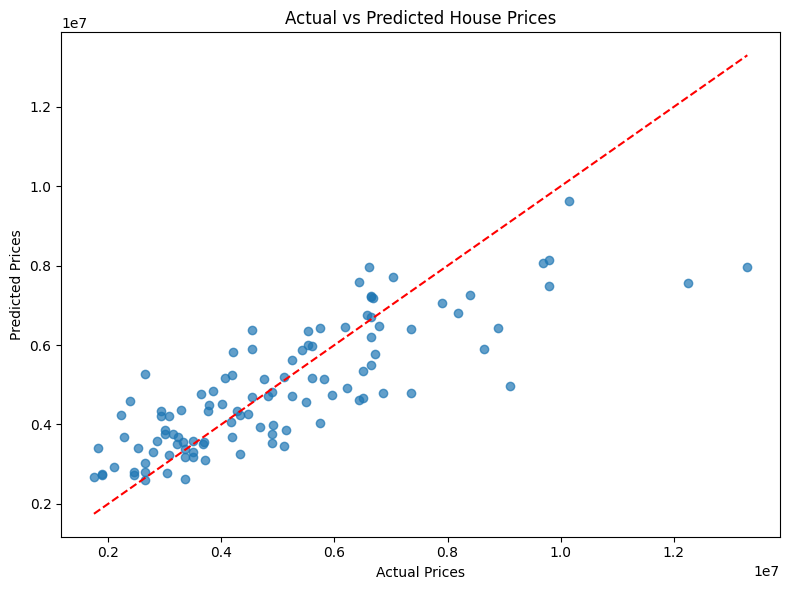

In [40]:
# Actual vs Predicted Price

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")

plt.tight_layout()

plt.savefig("screenshots/actual_vs_predicted.png", dpi=300)

plt.show()


### Observations: Actual vs Predicted House Prices

- The scatter plot compares actual house prices with the prices predicted by the Linear Regression model.
- The red dashed line represents perfect predictions.
- Most points are reasonably close to the reference line, indicating that the model captures some of the relationship between house features and prices.
- Some points are far from the line, showing differences between actual and predicted prices.
- The model tends to underestimate some of the higher-priced houses.

Overall, the model provides a reasonable baseline, but there is scope for improving prediction accuracy.


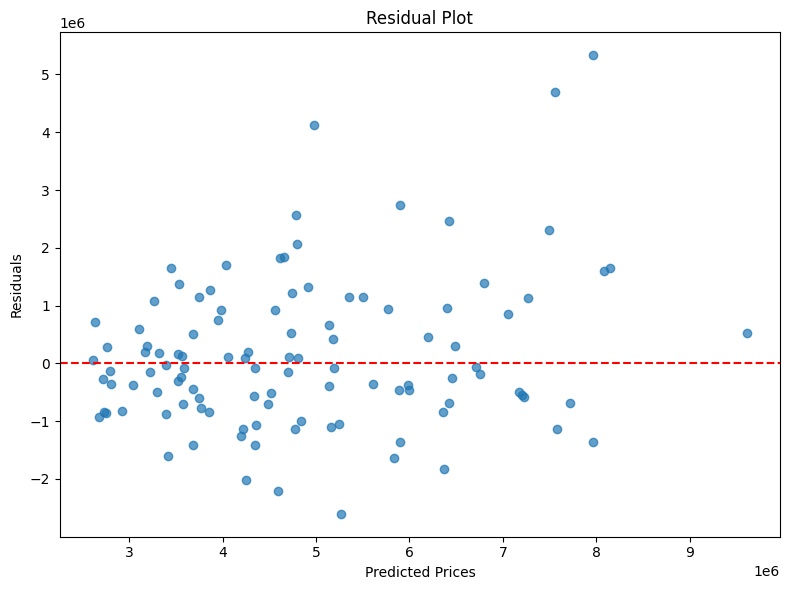

In [41]:
# Calculate residuals

residuals = y_test - y_pred

# Create residual plot

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

# Reference line at zero
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")

plt.tight_layout()

plt.savefig("screenshots/residual_plot.png", dpi=300)

plt.show()


### Residual Analysis

Residual analysis helps us understand the errors made by our Linear Regression model.

A residual is the difference between the actual house price and the predicted house price.

**Residual = Actual Price - Predicted Price**

The residual plot helps us:
- Identify how prediction errors are distributed.
- Check whether residuals are randomly scattered around zero.
- Identify patterns that may indicate limitations in the model.
- Understand whether the model consistently overestimates or underestimates prices.

A good residual plot generally shows randomly scattered points around the zero reference line without a clear pattern.


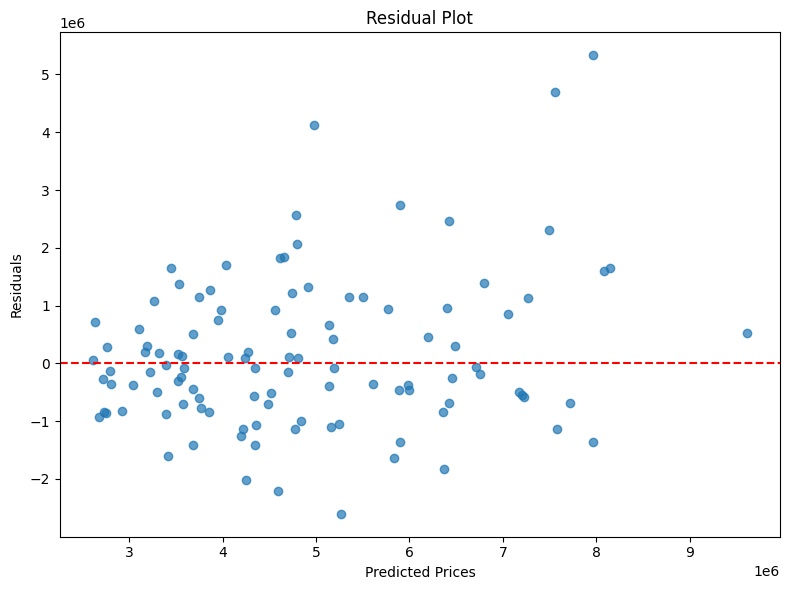

In [42]:
# Calculate residuals

residuals = y_test - y_pred

# Create residual plot

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

# Reference line at zero
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")

plt.tight_layout()

# Save the chart
plt.savefig("screenshots/residual_plot.png", dpi=300)

plt.show()


### Observations: Residual Plot

- The residual plot displays the differences between actual and predicted house prices.
- The red dashed line represents zero residual error.
- Points above the zero line indicate that the model underestimated house prices.
- Points below the zero line indicate that the model overestimated house prices.
- The distribution of residuals helps identify patterns and variations in prediction errors.

The residual plot is useful for understanding the limitations of the Linear Regression model and identifying areas where prediction accuracy could be improved.


In [43]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficients)

,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04


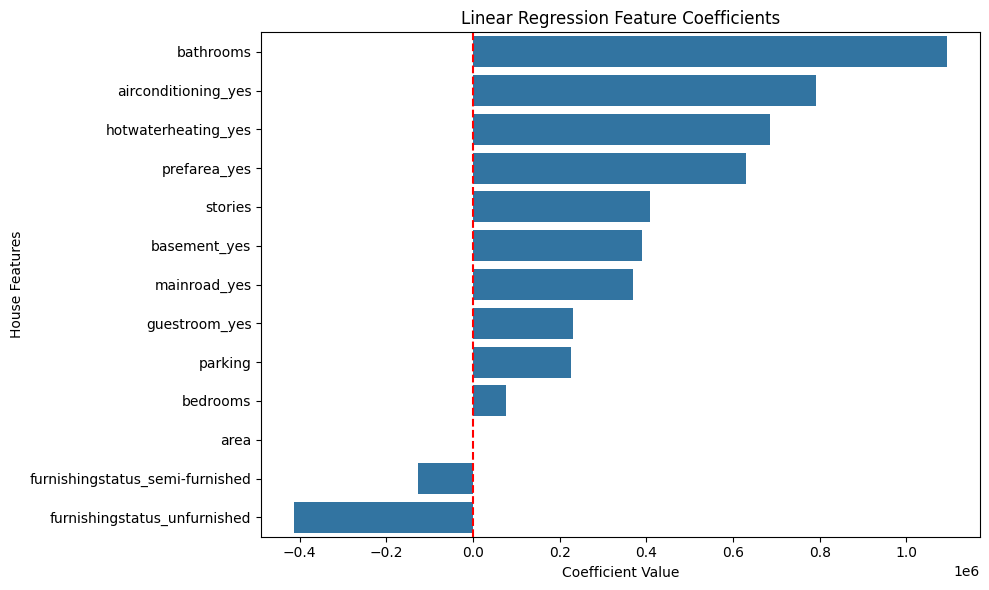

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("House Features")
plt.axvline(x=0, color="red", linestyle="--")
plt.tight_layout()

plt.savefig("screenshots/feature_coefficients.png", dpi=300)
plt.show()


### Observations: Feature Coefficients

- Bathrooms has the highest positive coefficient among the selected features.
- Air conditioning and hot water heating also have positive coefficients.
- Preferred area, stories, basement, and main road access show positive relationships with predicted house prices.
- Semi-furnished and unfurnished status have negative coefficients compared with the reference category, furnished.
- The area coefficient is positive, indicating that larger areas are associated with higher predicted prices.

Overall, the coefficient analysis shows how different house features influence the predictions made by the Linear Regression model. These coefficients represent associations within the model and do not necessarily indicate causation.


In [45]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [46]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=1.0, max_iter=10000))
])

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully!")
print("Lasso Regression model trained successfully!")

Ridge Regression model trained successfully!
Lasso Regression model trained successfully!


In [47]:
ridge_pred = ridge_model.predict(X_test)
lasso_pred = lasso_model.predict(X_test)

print("Ridge predictions completed!")
print("Lasso predictions completed!")

Ridge predictions completed!
Lasso predictions completed!


In [48]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})

display(model_comparison)

,Model,RMSE,R2 Score
0,Linear Regression,1.324507e+06,0.652924
1,Ridge Regression,1.324703e+06,0.652821
2,Lasso Regression,1.324507e+06,0.652924


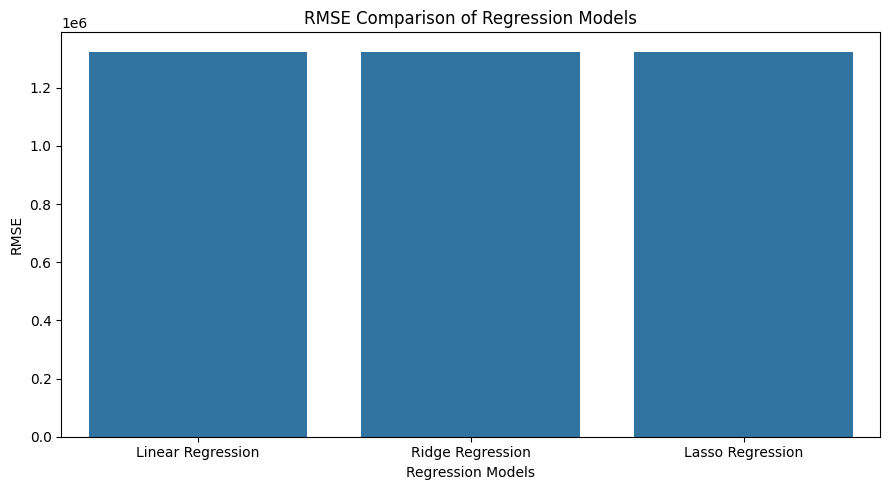

In [49]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.tight_layout()

plt.savefig("screenshots/model_rmse_comparison.png", dpi=300)
plt.show()

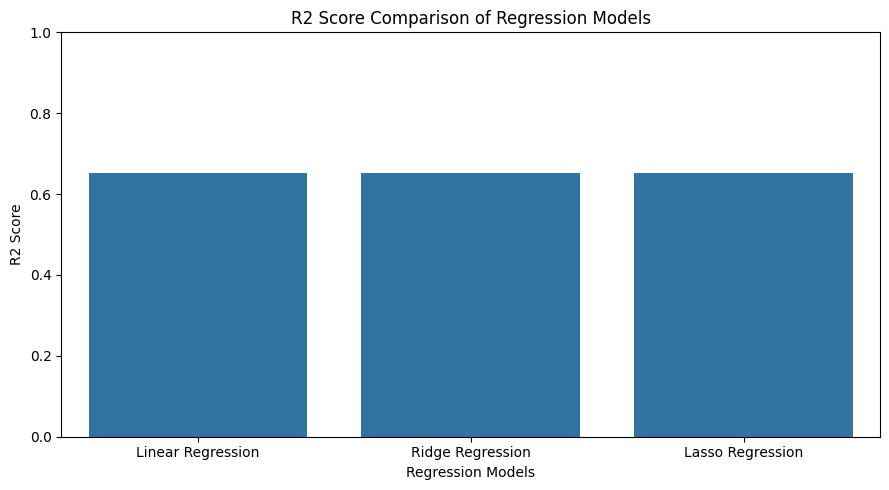

In [50]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("screenshots/model_r2_comparison.png", dpi=300)
plt.show()


## Ridge and Lasso Regression Comparison

### Observations

- Linear Regression achieved an R² score of approximately 0.653.
- Ridge Regression achieved a very similar R² score of approximately 0.653.
- Lasso Regression also performed almost identically to Linear Regression.
- Linear Regression and Lasso produced nearly identical RMSE values.
- Ridge Regression showed a slightly higher RMSE than the other two models.
- The comparison charts show that regularization did not significantly improve model performance.

### Conclusion

Among the three models, Linear Regression and Lasso Regression achieved almost identical performance, while Ridge Regression performed slightly worse.

For this dataset and the selected parameters, regularization did not provide a meaningful improvement in prediction accuracy. Linear Regression remains a suitable baseline model for this house price prediction project.



# Final Conclusion

In this project, a House Price Prediction model was developed using Linear Regression and the Housing dataset.

The dataset contained 545 records and 13 columns, including house area, bedrooms, bathrooms, stories, parking, and furnishing status.

The project involved data inspection, exploratory data analysis, feature selection, One-Hot Encoding, correlation analysis, model training, and performance evaluation.

The Linear Regression model achieved an R² score of approximately 0.653 and an RMSE of approximately 1,324,507.

Ridge and Lasso Regression were also implemented and compared with the Linear Regression model. Their performance was almost identical, with no significant improvement in prediction accuracy.

Overall, this project demonstrates how machine learning can be used to estimate house prices based on different property features.

## Recommendations and Future Improvements

1. Use more data: A larger dataset with additional property details could improve prediction accuracy.
2. Include additional features: House age, exact location, nearby facilities, and property condition could provide more useful information.
3. Experiment with other algorithms: Random Forest, Decision Tree, and Gradient Boosting could be tested against Linear Regression.
4. Improve model performance: Hyperparameter tuning and feature engineering could help reduce prediction errors.
5. Develop a prediction application: The trained model could be integrated into a web application where users enter house details and receive an estimated price.
